# 数据地址

https://zenodo.org/records/4751624?utm_source=chatgpt.com

In [1]:
from pathlib import Path

PATH_HER2 = Path(r"E:\Data\HER2")

# 查看层级关系

HER2 dataset → Patient / Sample → Tissue section → Spot \
Patient / Sample：A、B、C、D、E、F、G、H，共 8 个患者/样本\
Tissue section：每个 Patient 下有多张组织切片。A-D 各有 6 张 section，E-H 各有 3 张 section，共 36 张\
例如： \
A：Patient A\
A1：Patient A 的第 1 张 tissue section\
A2：Patient A 的另一张 tissue section，不是另一个 Patient\
每一张 tissue section 都有三类核心文件以 A1 为例：\
A1.tsv.gz：A1 这张 section 的 Spot × Gene 表达矩阵，记录每个 spot 的基因表达\
A1_selection.tsv.gz：A1 这张 section 的 spot 空间信息，记录 spot 的空间/图像位置\
HE/A1.jpg：A1 这张 section 对应的 H&E 图像\
因此，同一个 section 的数据通过 section 名称对应： \
A1.tsv.gz ↔ A1_selection.tsv.gz ↔ HE/A1.jpg \
annotation/A1.jpg：A1 的病理 annotation 图。annotation 文件夹一共只有 A1、B1、C1、D1、E1、F1、G1、H1 共 8 张，也就是每个 Patient 只提供第 1 张 section 的 annotation 图。

In [2]:
from pathlib import Path
from collections import defaultdict
import re

count_folder = PATH_HER2 / "count-matrices"
image_folder = PATH_HER2 / "images"
spot_folder = PATH_HER2 / "spot-selections"

# =========================================
# 1. 收集三个文件夹中的文件
# =========================================

count_files = sorted([p for p in count_folder.rglob("*") if p.is_file()])
image_files = sorted([p for p in image_folder.rglob("*") if p.is_file()])
spot_files = sorted([p for p in spot_folder.rglob("*") if p.is_file()])

print("===== 文件总数 =====")
print("count:", len(count_files))
print("image:", len(image_files))
print("spot:", len(spot_files))


# =========================================
# 2. 从文件名提取 section，例如 A1、B3、H2
# =========================================

def extract_section(filename):
    m = re.search(r'([A-H]\d+)', filename)
    if m:
        return m.group(1)
    return None


# =========================================
# 3. 建立 section -> 文件路径映射
# =========================================

count_map = defaultdict(list)
image_map = defaultdict(list)
spot_map = defaultdict(list)

for p in count_files:
    section = extract_section(p.name)
    if section:
        count_map[section].append(p)

for p in image_files:
    section = extract_section(p.name)
    if section:
        image_map[section].append(p)

for p in spot_files:
    section = extract_section(p.name)
    if section:
        spot_map[section].append(p)

# =========================================
# 4. 建立 Patient -> Section 层级
# =========================================

all_sections = sorted(
    set(count_map.keys()) |
    set(image_map.keys()) |
    set(spot_map.keys()),
    key=lambda x: (x[0], int(x[1:]))
)

patient_sections = defaultdict(list)

for section in all_sections:
    patient = section[0]
    patient_sections[patient].append(section)

# =========================================
# 5. 打印 Patient -> Tissue Section 层级
# =========================================

print("\n===== HER2 层级关系 =====")

for patient in sorted(patient_sections.keys()):

    sections = patient_sections[patient]

    print(f"\nPatient / Sample {patient}")
    print(f"Section 数量: {len(sections)}")

    for section in sections:
        print(f"  └── Tissue section {section}")

# =========================================
# 6. 打印每个 section 对应的数据文件
# =========================================

print("\n\n===== Section -> 数据文件对应关系 =====")

for section in all_sections:

    print(f"\n[{section}]")

    print("  Count matrix:")
    if section in count_map:
        for p in count_map[section]:
            print("   ", p.relative_to(PATH_HER2))
    else:
        print("    无")

    print("  Spot selection:")
    if section in spot_map:
        for p in spot_map[section]:
            print("   ", p.relative_to(PATH_HER2))
    else:
        print("    无")

    print("  Image:")
    if section in image_map:
        for p in image_map[section]:
            print("   ", p.relative_to(PATH_HER2))
    else:
        print("    无")

# =========================================
# 7. 专门打印 image 的完整路径
#    用来检查为什么 36 个 section 有 44 张 image
# =========================================

print("\n\n===== 所有 image 完整相对路径 =====")

for p in image_files:
    print(p.relative_to(image_folder))

# =========================================
# 8. 汇总
# =========================================

print("\n\n===== 汇总 =====")

print("Patient 数量:", len(patient_sections))
print("Section 数量:", len(all_sections))

for patient in sorted(patient_sections.keys()):
    print(
        patient,
        "->",
        patient_sections[patient],
        f"({len(patient_sections[patient])} sections)"
    )

===== 文件总数 =====
count: 36
image: 44
spot: 36

===== HER2 层级关系 =====

Patient / Sample A
Section 数量: 6
  └── Tissue section A1
  └── Tissue section A2
  └── Tissue section A3
  └── Tissue section A4
  └── Tissue section A5
  └── Tissue section A6

Patient / Sample B
Section 数量: 6
  └── Tissue section B1
  └── Tissue section B2
  └── Tissue section B3
  └── Tissue section B4
  └── Tissue section B5
  └── Tissue section B6

Patient / Sample C
Section 数量: 6
  └── Tissue section C1
  └── Tissue section C2
  └── Tissue section C3
  └── Tissue section C4
  └── Tissue section C5
  └── Tissue section C6

Patient / Sample D
Section 数量: 6
  └── Tissue section D1
  └── Tissue section D2
  └── Tissue section D3
  └── Tissue section D4
  └── Tissue section D5
  └── Tissue section D6

Patient / Sample E
Section 数量: 3
  └── Tissue section E1
  └── Tissue section E2
  └── Tissue section E3

Patient / Sample F
Section 数量: 3
  └── Tissue section F1
  └── Tissue section F2
  └── Tissue section F3

Patien

# 看一个sample，一个tissue的表达 - A1.tsv.gz

A1.tsv.gz：Patient A 的第 1 张 tissue section（A1）的 Spot × Gene 表达矩阵\
shape = (346, 15045)：A1 这张切片中共有 346 个 spot，检测了 15045 个 gene\
行（index）：每一行代表一个 spot\
例如：10x13、10x14、10x15、10x16、10x17 这些就是 spot ID\
列（columns）：每一列代表一个 gene\
例如：FO538757.1、SAMD11、NOC2L、KLHL17、PLEKHN1 等\
矩阵中的数值：表示某个 spot 中某个 gene 的表达 count\
例如：10x13 这个 spot 中，SAMD11 = 6，说明这个 spot 里该基因检测到 6 个 count\
所以这个文件可以理解为：\
Spot × Gene\
也就是：346 个 spot × 15045 个 gene

In [3]:
import pandas as pd

file_path = PATH_HER2 / "count-matrices" / "A1.tsv.gz"

df = pd.read_csv(
    file_path,
    sep="\t",
    index_col=0
)

print("shape:")
print(df.shape)

print("\n前5个 spot ID:")
print(df.index[:5].tolist())

print("\n前10个 gene:")
print(df.columns[:10].tolist())

print("\n前5行前10列:")
print(df.iloc[:5, :10])

print("\n数据类型:")
print(df.dtypes.head(10))
print("\n行数（spot 数）:", df.shape[0])
print("列数（gene 数）:", df.shape[1])

shape:
(346, 15045)

前5个 spot ID:
['10x13', '10x14', '10x15', '10x16', '10x17']

前10个 gene:
['FO538757.1', 'SAMD11', 'NOC2L', 'KLHL17', 'PLEKHN1', 'PERM1', 'HES4', 'ISG15', 'AGRN', 'RNF223']

前5行前10列:
       FO538757.1  SAMD11  NOC2L  KLHL17  PLEKHN1  PERM1  HES4  ISG15  AGRN  \
10x13           0       6      1       0        0      0     2      0     0   
10x14           0       6      3       1        0      0     3      0     1   
10x15           1       1      0       0        0      0     6      1     2   
10x16           0       6      1       0        0      0     3      0     0   
10x17           0       1      2       0        0      0     4      0     1   

       RNF223  
10x13       0  
10x14       0  
10x15       0  
10x16       0  
10x17       0  

数据类型:
FO538757.1    int64
SAMD11        int64
NOC2L         int64
KLHL17        int64
PLEKHN1       int64
PERM1         int64
HES4          int64
ISG15         int64
AGRN          int64
RNF223        int64
dtype: object

行数（spo

# 拆解上述所对应的 - A1_selection.tsv.gz

A1_selection.tsv.gz：记录 A1 这张 tissue section 中每个 spot 的空间位置和图像像素位置 \
shape = (348, 7)：A1 的 spot-selection 文件里有 348 条 spot 记录、7 个字段 \
x：spot 在原始空间阵列中的 x 坐标\
y：spot 在原始空间阵列中的 y 坐标\
new_x：经过几何校正/变换后的 x 坐标\
new_y：经过几何校正/变换后的 y 坐标\
pixel_x：这个 spot 在 H&E 图像中的像素 x 坐标\
pixel_y：这个 spot 在 H&E 图像中的像素 y 坐标\
selected：这个 spot 是否被选中用于分析，1 表示选中\
最关键的是：
x + y 可以组成和表达矩阵里一致的 spot ID\
例如： x = 10    y = 13
就对应：10x13
也就是说：A1.tsv.gz 里的 10x13可以和A1_selection.tsv.gz 里 x=10, y=13对应起来\
然后这个 spot 又有自己的：pixel_x / pixel_y\
所以就能进一步在 HE/A1.jpg 上找到它的位置

In [4]:
import pandas as pd

file_path = PATH_HER2 / "spot-selections" / "A1_selection.tsv.gz"

df_sel = pd.read_csv(
    file_path,
    sep="\t"
)

print("shape:")
print(df_sel.shape)

print("\ncolumns:")
print(df_sel.columns.tolist())

print("\n前5行:")
print(df_sel.head())

print("\n数据类型:")
print(df_sel.dtypes)

shape:
(348, 7)

columns:
['x', 'y', 'new_x', 'new_y', 'pixel_x', 'pixel_y', 'selected']

前5行:
    x   y   new_x   new_y  pixel_x  pixel_y  selected
0  22  12  21.939  11.948  4550.31  2394.07         1
1  21  12  20.918  11.969  4328.43  2398.66         1
2  16  12  15.999  11.995  3259.47  2404.35         1
3  20  12  20.128  11.977  4156.75  2400.41         1
4  26  12  26.018  11.992  5436.72  2403.69         1

数据类型:
x             int64
y             int64
new_x       float64
new_y       float64
pixel_x     float64
pixel_y     float64
selected      int64
dtype: object


# 拆解上述所对应的 - HE/A1.jpg

HE/A1.jpg：Patient A 的第 1 张 tissue section（A1）对应的 H&E 组织切片图像\
图像尺寸 = (6954, 7435)：宽 6954 像素，高 7435 像素\
数组 shape = (7435, 6954, 3)：7435 行、6954 列、3 个 RGB 通道\
dtype = uint8：每个颜色通道取值范围是 0–255\
RGB：这是彩色 H&E 图像，不是单通道灰度图\
图上的：深紫色区域主要是细胞核/核密集区域  粉红色区域主要是细胞质、基质等组织成分  浅色/空白区域是组织之外的背景  背景上还能看到规则排列的淡圆点，这些就是 ST array 上的 spot 位置痕迹/阵列结构\
最关键的是，这张图可以和 A1_selection.tsv.gz 直接联系起来：pixel_x、pixel_y 就是在这张 6954 × 7435 H&E 图上的像素坐标\
也就是说：A1.tsv.gz 中的 spot 10x13\
→ 在 A1_selection.tsv.gz 找到 x=10, y=13\
→ 得到该 spot 的 pixel_x, pixel_y\
→ 直接定位到 HE/A1.jpg 上。

图像尺寸:
(6954, 7435)

图像模式:
RGB

数组 shape:
(7435, 6954, 3)

数据类型:
uint8

像素值范围:
0 255


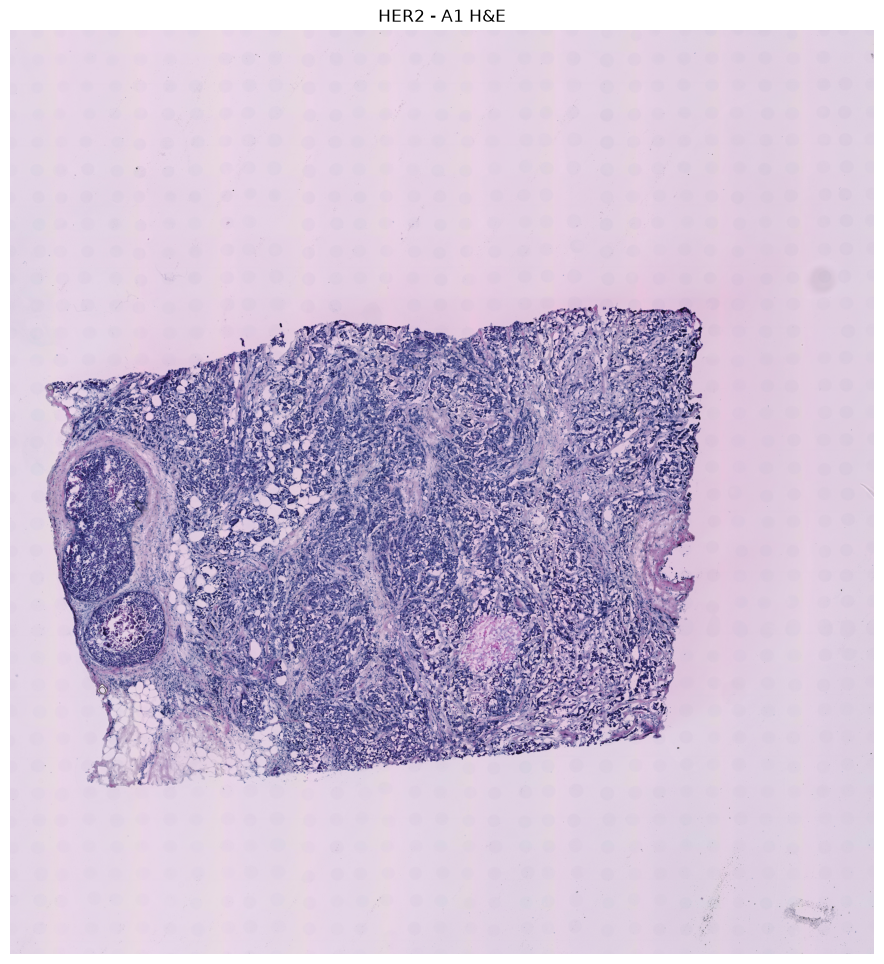

In [5]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

file_path = PATH_HER2 / "images" / "HE" / "A1.jpg"

img = Image.open(file_path).convert("RGB")

print("图像尺寸:")
print(img.size)  # (width, height)

print("\n图像模式:")
print(img.mode)

img_array = np.array(img)

print("\n数组 shape:")
print(img_array.shape)

print("\n数据类型:")
print(img_array.dtype)

print("\n像素值范围:")
print(img_array.min(), img_array.max())

plt.figure(figsize=(12, 12))
plt.imshow(img)
plt.axis("off")
plt.title("HER2 - A1 H&E")
plt.show()

# A1 annotation image

annotation/A1.jpg：是在 HE/A1.jpg 的 H&E 图像基础上，由人工勾画出的病理/组织区域标注图\
彩色轮廓：表示不同的组织或病理区域\
作用：不是新的成像数据，而是给 H&E 图像增加区域标签，后续可以判断某个 spot 位于哪类组织区域\
它和前面的数据关系是：spot ID → pixel_x / pixel_y → H&E 上的位置 → annotation 区域\
所以一个 spot 最终不仅可以知道：这个位置表达了哪些 gene\
还可以进一步知道：这个位置属于哪个病理区域

图像尺寸:
(5774, 6174)

图像模式:
RGB

数组 shape:
(6174, 5774, 3)

数据类型:
uint8

像素值范围:
0 255


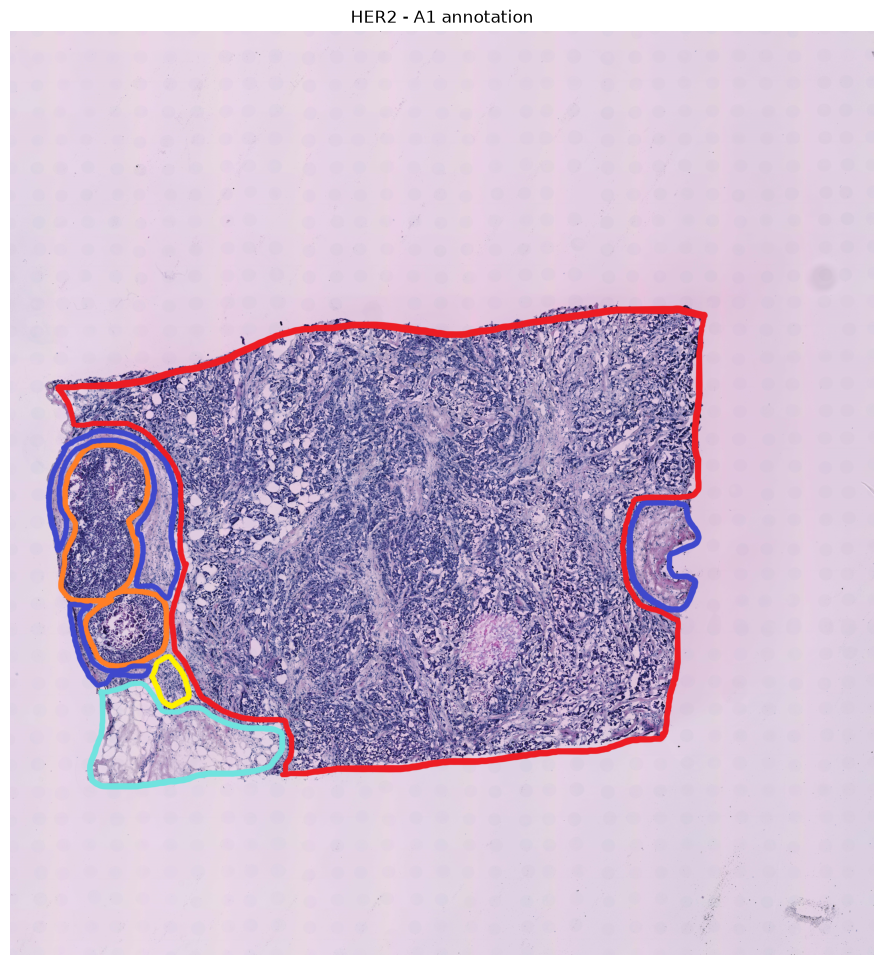

In [6]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

file_path = PATH_HER2 / "images" / "annotation" / "A1.jpg"

img = Image.open(file_path).convert("RGB")

print("图像尺寸:")
print(img.size)

print("\n图像模式:")
print(img.mode)

img_array = np.array(img)

print("\n数组 shape:")
print(img_array.shape)

print("\n数据类型:")
print(img_array.dtype)

print("\n像素值范围:")
print(img_array.min(), img_array.max())

plt.figure(figsize=(12, 12))
plt.imshow(img)
plt.axis("off")
plt.title("HER2 - A1 annotation")
plt.show()

# 数据对齐

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image

# =========================================================
# 1. 原始数据路径
# =========================================================

PATH_HER2 = Path(r"E:\Data\HER2")
section = "A1"

count_path = PATH_HER2 / "count-matrices" / f"{section}.tsv.gz"
spot_path = PATH_HER2 / "spot-selections" / f"{section}_selection.tsv.gz"
image_path = PATH_HER2 / "images" / "HE" / f"{section}.jpg"

# =========================================================
# 2. 输出路径：当前工作目录 / processed_data
# =========================================================

output_root = Path.cwd() / "processed_data" / "HER2"
section_dir = output_root / section
patch_dir = section_dir / "images"

section_dir.mkdir(parents=True, exist_ok=True)
patch_dir.mkdir(parents=True, exist_ok=True)

print("当前工作目录:")
print(Path.cwd())

print("\n处理结果目录:")
print(output_root)


# =========================================================
# 3. 读取 Spot × Gene 表达矩阵
# =========================================================

expr = pd.read_csv(
    count_path,
    sep="\t",
    index_col=0
)

print("\nExpression shape:")
print(expr.shape)

print("\n前5个 spot:")
print(expr.index[:5].tolist())


# =========================================================
# 4. 读取 spot 空间坐标
# =========================================================

spots = pd.read_csv(
    spot_path,
    sep="\t"
)

print("\nSpot selection shape:")
print(spots.shape)

print("\ncolumns:")
print(spots.columns.tolist())


# =========================================================
# 5. 根据 x 和 y 构造 spot ID
#    例如 x=10, y=13 -> 10x13
# =========================================================

spots["spot_id"] = (
    spots["x"].astype(int).astype(str)
    + "x"
    + spots["y"].astype(int).astype(str)
)

print("\n构造后的 spot ID:")
print(spots["spot_id"].head().tolist())


# =========================================================
# 6. 只保留 selected == 1 的 spot
# =========================================================

spots = spots[spots["selected"] == 1].copy()

print("\nselected spot 数量:")
print(len(spots))


# =========================================================
# 7. expression 与 spatial information 按 spot ID 对齐
# =========================================================

expr_spots = set(expr.index.astype(str))
spatial_spots = set(spots["spot_id"].astype(str))

common_spots = sorted(
    expr_spots.intersection(spatial_spots)
)

print("\nExpression spot 数量:")
print(len(expr_spots))

print("Spatial spot 数量:")
print(len(spatial_spots))

print("共同 spot 数量:")
print(len(common_spots))

print("\nExpression 中没有 spatial 信息的 spot:")
print(sorted(expr_spots - spatial_spots))

print("\nSpatial 中没有 expression 的 spot:")
print(sorted(spatial_spots - expr_spots))


# =========================================================
# 8. 按共同 spot 重新排序
# =========================================================

expr_aligned = expr.loc[common_spots].copy()

spots_aligned = (
    spots
    .set_index("spot_id")
    .loc[common_spots]
    .copy()
)

print("\n对齐后 expression:")
print(expr_aligned.shape)

print("对齐后 spatial:")
print(spots_aligned.shape)

print("\nID 是否完全一致:")
print(
    list(expr_aligned.index)
    ==
    list(spots_aligned.index)
)


# =========================================================
# 9. 读取整张 H&E
# =========================================================

he_img = Image.open(image_path).convert("RGB")

print("\nH&E size:")
print(he_img.size)


# =========================================================
# 10. 裁取每个 spot 对应的 1120 × 1120 H&E patch
# =========================================================

PATCH_SIZE = 1120
HALF_SIZE = PATCH_SIZE // 2

data_list = []

for spot_id in common_spots:

    row = spots_aligned.loc[spot_id]

    pixel_x = float(row["pixel_x"])
    pixel_y = float(row["pixel_y"])

    cx = int(round(pixel_x))
    cy = int(round(pixel_y))

    left = cx - HALF_SIZE
    top = cy - HALF_SIZE
    right = cx + HALF_SIZE
    bottom = cy + HALF_SIZE

    # 按 spot 中心裁 1120 × 1120 H&E patch
    patch = he_img.crop(
        (left, top, right, bottom)
    )

    patch_name = f"{spot_id}.jpg"
    patch_path = patch_dir / patch_name

    patch.save(
        patch_path,
        quality=95
    )

    # 当前 spot 的完整 gene expression
    label = expr_aligned.loc[spot_id].to_numpy(
        dtype=np.float32
    )

    # 保存相对于 processed_data 的图像路径
    relative_img_path = (
        Path(section)
        / "images"
        / patch_name
    )

    sample = {
        "spot_id": spot_id,
        "img_path": relative_img_path.as_posix(),
        "label": label,
        "pixel_position": np.array(
            [pixel_x, pixel_y],
            dtype=np.float32
        )
    }

    data_list.append(sample)


# =========================================================
# 11. 保存为 npy
# =========================================================

npy_path = section_dir / f"{section}.npy"

np.save(
    npy_path,
    np.array(data_list, dtype=object),
    allow_pickle=True
)

print("\n保存完成:")
print(npy_path)

print("\n样本数量:")
print(len(data_list))


# =========================================================
# 12. 验证生成的 npy
# =========================================================

check = np.load(
    npy_path,
    allow_pickle=True
).tolist()

print("\n第一个样本:")
print("spot_id:", check[0]["spot_id"])
print("img_path:", check[0]["img_path"])
print("label shape:", check[0]["label"].shape)
print("pixel_position:", check[0]["pixel_position"])

print("\n前10个 gene:")
print(expr.columns[:10].tolist())

print("\n对应前10个表达值:")
print(check[0]["label"][:10])

当前工作目录:
E:\PythonProject\demo-python

处理结果目录:
E:\PythonProject\demo-python\processed_data\HER2

Expression shape:
(346, 15045)

前5个 spot:
['10x13', '10x14', '10x15', '10x16', '10x17']

Spot selection shape:
(348, 7)

columns:
['x', 'y', 'new_x', 'new_y', 'pixel_x', 'pixel_y', 'selected']

构造后的 spot ID:
['22x12', '21x12', '16x12', '20x12', '26x12']

selected spot 数量:
348

Expression spot 数量:
346
Spatial spot 数量:
348
共同 spot 数量:
346

Expression 中没有 spatial 信息的 spot:
[]

Spatial 中没有 expression 的 spot:
['17x14', '18x20']

对齐后 expression:
(346, 15045)
对齐后 spatial:
(346, 7)

ID 是否完全一致:
True

H&E size:
(6954, 7435)

保存完成:
E:\PythonProject\demo-python\processed_data\HER2\A1\A1.npy

样本数量:
346

第一个样本:
spot_id: 10x13
img_path: A1/images/10x13.jpg
label shape: (15045,)
pixel_position: [1923.65 2622.15]

前10个 gene:
['FO538757.1', 'SAMD11', 'NOC2L', 'KLHL17', 'PLEKHN1', 'PERM1', 'HES4', 'ISG15', 'AGRN', 'RNF223']

对应前10个表达值:
[0. 6. 1. 0. 0. 0. 2. 0. 0. 0.]
